In [1]:
import yfinance as yf #importando a biblioteca yfinance 

In [2]:


df = yf.download("BOVA11.SA", start="2015-01-01", multi_level_index = False) #baixando os dados do ativo BOVA11.SA a partir de 2015-01-01 e armazenando em um dataframe chamado df

[*********************100%***********************]  1 of 1 completed


In [3]:
df.head() #usando a função head() para exibir as primeiras linhas do dataframe df


,Close,High,Low,Open,Volume
Date,,,,,
2015-01-02,47.259998,48.340000,46.970001,48.130001,2755220
2015-01-05,46.320000,46.650002,45.990002,46.500000,963480
2015-01-06,46.580002,46.750000,46.009998,46.490002,2024030
2015-01-07,48.150002,48.529999,47.099998,47.099998,1534970
2015-01-08,48.509998,48.889999,47.619999,48.330002,2070130


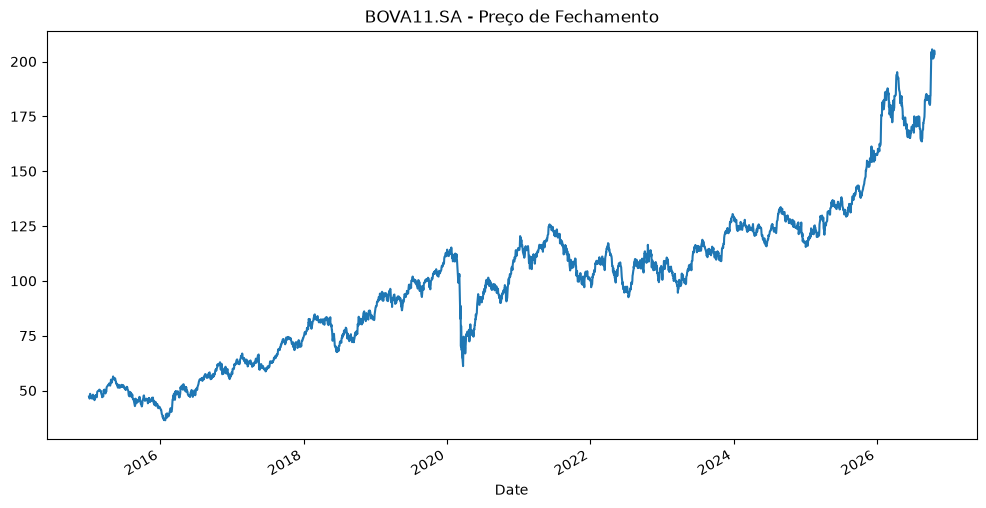

In [4]:
df["Close"].plot(title = "BOVA11.SA - Preço de Fechamento", figsize = (12,6)); #plotando o gráfico do preço de fechamento do ativo BOVA11.SA

In [5]:
df["retorno"] = df["Close"].pct_change()
df["retorno_amanha"] = df["retorno"].shift(-1)
df = df.dropna()
df["y"] = (df["retorno_amanha"] > 0).astype(int)
df.head()

,Close,High,Low,Open,Volume,retorno,retorno_amanha,y
Date,,,,,,,,
2015-01-05,46.320000,46.650002,45.990002,46.500000,963480,-0.019890,0.005613,1
2015-01-06,46.580002,46.750000,46.009998,46.490002,2024030,0.005613,0.033705,1
2015-01-07,48.150002,48.529999,47.099998,47.099998,1534970,0.033705,0.007477,1
2015-01-08,48.509998,48.889999,47.619999,48.330002,2070130,0.007477,-0.020202,0
2015-01-09,47.529999,48.259998,47.220001,48.240002,2751700,-0.020202,-0.014727,0


In [6]:
df["y"].value_counts() 

y
1    1534
0    1401
Name: count, dtype: int64

In [7]:
df["y"].mean() #vale ressaltar que um modelo que chuta sempre que o preço vai subir, acertaria 52% das vezes.

np.float64(0.5226575809199319)

In [8]:
df["retorno_ontem"] = df["retorno"].shift(1)
df["media_movel_5"] = df["retorno"].rolling(5).mean()
df["volatilidade_5"] = df["retorno"].rolling(5).std()
#df["Close"] quer dizer que estamos trabalhando somente com a coluna Close(fechamento, que significa o valor que a moeda fechou no final do dia)
df = df.dropna() #removendo os valores nulos do dataframe df

In [9]:
df.head()

,Close,High,Low,Open,Volume,retorno,retorno_amanha,y,retorno_ontem,media_movel_5,volatilidade_5
Date,,,,,,,,,,,
2015-01-09,47.529999,48.259998,47.220001,48.240002,2751700,-0.020202,-0.014727,0,0.007477,0.001341,0.022462
2015-01-12,46.830002,47.439999,46.680000,47.299999,2783990,-0.014727,-0.004057,0,-0.020202,0.002373,0.021333
2015-01-13,46.639999,47.639999,46.639999,46.880001,4836250,-0.004057,-0.003431,0,-0.014727,0.000439,0.021404
2015-01-14,46.480000,46.990002,46.110001,46.200001,2432730,-0.003431,0.011188,1,-0.004057,-0.006988,0.010782
2015-01-15,47.000000,47.529999,46.490002,46.540001,2525830,0.011188,0.012766,1,-0.003431,-0.006246,0.012076


In [10]:
X = df[["retorno", "retorno_ontem", "media_movel_5", "volatilidade_5"]]
y = df["y"]
corte = int(len(df) * 0.8)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]
y_train = y.iloc[:corte]
y_test = y.iloc[corte:]

In [11]:
print(len(X_train), len(X_test))
print(X_train.index[-1], X_test.index[0])

2344 587
2024-06-13 00:00:00 2024-06-14 00:00:00


In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

print("Acerto do modelo no teste:", model.score(X_test, y_test))
print("Baseline no teste:", max(y_test.mean(), 1 - y_test.mean()))

Acerto do modelo no teste: 0.5298126064735945
Baseline no teste: 0.5281090289608177


In [13]:
import pandas as pd

pred = model.predict(X_test)
print(pd.Series(pred).value_counts())

1    586
0      1
Name: count, dtype: int64
